In [10]:
import pandas as pd

In [11]:
import numpy as np

In [12]:
import matplotlib.pyplot as plt

In [13]:
pd.set_option("display.max_columns", None)

In [14]:
from pathlib import Path

DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
path = "titanic.csv" if Path("titanic.csv").exists() else DATA_URL

df = pd.read_csv(path)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
# PART ONE: EXPLORING THE DATASET
print("Rows, Columns:", df.shape)

Rows, Columns: (891, 12)


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [17]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [18]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [19]:
# The same as a percentage of all rows, which is easier to judge
missing_pct = (df.isnull().mean() * 100).round(1)
missing_pct[missing_pct > 0].sort_values(ascending=False)

Cabin       77.1
Age         19.9
Embarked     0.2
dtype: float64

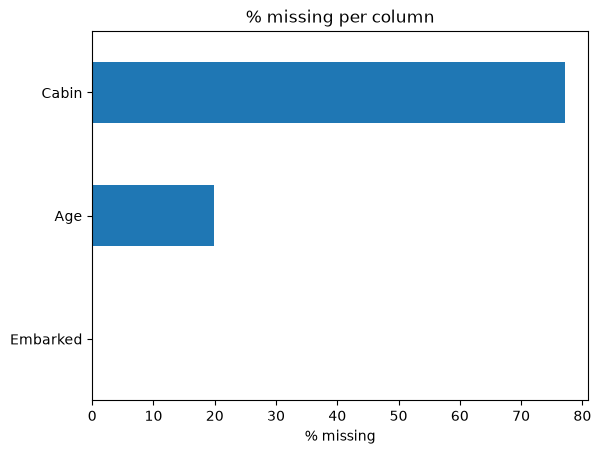

In [20]:
missing_pct[missing_pct > 0].sort_values().plot(kind="barh", title="% missing per column")
plt.xlabel("% missing")
plt.show()

In [21]:
# How many rows are exact copies of an earlier row?
df.duplicated().sum()

np.int64(0)

In [22]:
df_with_dupes = pd.concat([df, df.head(3)], ignore_index=True)

print("Rows:", len(df_with_dupes))
print("Duplicates:", df_with_dupes.duplicated().sum())

# Show the duplicated rows (keep=False marks every copy, including the original)
df_with_dupes[df_with_dupes.duplicated(keep=False)]

Rows: 894
Duplicates: 3


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
891,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
892,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
893,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [23]:
# Remove them: keeps the first copy of each row
df_no_dupes = df_with_dupes.drop_duplicates()
print("Rows after drop_duplicates():", len(df_no_dupes))

Rows after drop_duplicates(): 891


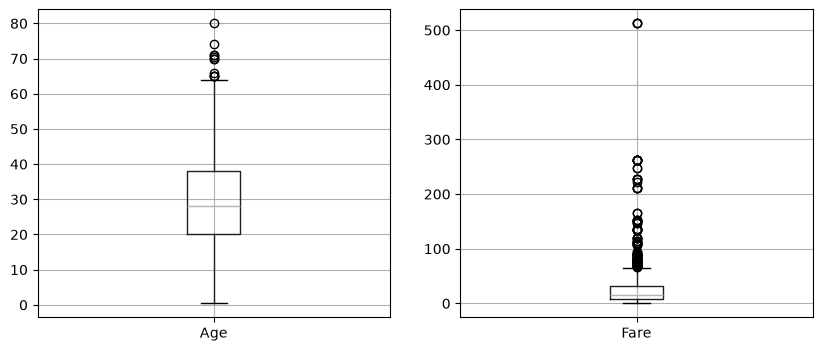

In [24]:
#Handling outliers
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df.boxplot(column="Age", ax=axes[0])
df.boxplot(column="Fare", ax=axes[1])
plt.show()

In [25]:
def iqr_bounds(column):
    q1 = column.quantile(0.25)
    q3 = column.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

lower, upper = iqr_bounds(df["Fare"])
print(f"Fare: normal range is {lower:.2f} to {upper:.2f}")

fare_outliers = df[(df["Fare"] < lower) | (df["Fare"] > upper)]
print("Number of Fare outliers:", len(fare_outliers))
fare_outliers[["Name", "Pclass", "Fare"]].sort_values("Fare", ascending=False).head()

Fare: normal range is -26.72 to 65.63
Number of Fare outliers: 116


,Name,Pclass,Fare
258,"Ward, Miss. Anna",1,512.3292
737,"Lesurer, Mr. Gustave J",1,512.3292
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
27,"Fortune, Mr. Charles Alexander",1,263.0000
341,"Fortune, Miss. Alice Elizabeth",1,263.0000


In [26]:
clean = df.copy()

In [27]:
print("Mean age:  ", round(clean["Age"].mean(), 2))
print("Median age:", clean["Age"].median())

Mean age:   29.7
Median age: 28.0


In [28]:
# Optional but useful: remember which rows were filled in
clean["Age_was_missing"] = clean["Age"].isnull().astype(int)

# Median imputation
clean["Age"] = clean["Age"].fillna(clean["Age"].median())

# (Mean imputation would be: clean["Age"].fillna(clean["Age"].mean()))
print("Missing Age values now:", clean["Age"].isnull().sum())

Missing Age values now: 0


In [29]:
most_common_port = clean["Embarked"].mode()[0]
print("Most common port:", most_common_port)

clean["Embarked"] = clean["Embarked"].fillna(most_common_port)
print("Missing Embarked values now:", clean["Embarked"].isnull().sum())

Most common port: S
Missing Embarked values now: 0


In [30]:
clean = clean.drop(columns=["Cabin"])
clean.isnull().sum()

PassengerId        0
Survived           0
Pclass             0
Name               0
Sex                0
Age                0
SibSp              0
Parch              0
Ticket             0
Fare               0
Embarked           0
Age_was_missing    0
dtype: int64

Max fare before: 512.33
Max fare after:  65.63


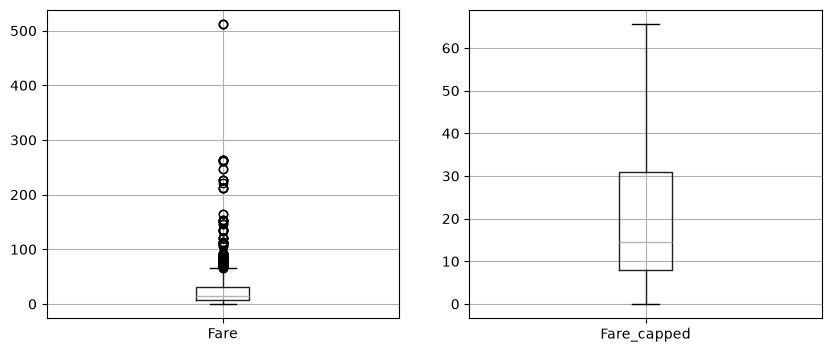

In [31]:
lower, upper = iqr_bounds(clean["Fare"])
clean["Fare_capped"] = clean["Fare"].clip(lower=lower, upper=upper)

print(f"Max fare before: {clean['Fare'].max():.2f}")
print(f"Max fare after:  {clean['Fare_capped'].max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
clean.boxplot(column="Fare", ax=axes[0])
clean.boxplot(column="Fare_capped", ax=axes[1])
plt.show()

In [32]:
clean["Sex_encoded"] = clean["Sex"].map({"male": 0, "female": 1})
clean[["Sex", "Sex_encoded"]].head()

,Sex,Sex_encoded
0,male,0
1,female,1
2,female,1
3,female,1
4,male,0


In [33]:
embarked_dummies = pd.get_dummies(clean["Embarked"], prefix="Embarked", dtype=int)
pd.concat([clean["Embarked"], embarked_dummies], axis=1).head()

,Embarked,Embarked_C,Embarked_Q,Embarked_S
0,S,0,0,1
1,C,1,0,0
2,S,0,0,1
3,S,0,0,1
4,S,0,0,1


In [34]:
clean = pd.concat([clean, embarked_dummies], axis=1)

In [35]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

cols = ["Age", "Fare_capped"]

minmax = MinMaxScaler().fit_transform(clean[cols])
standard = StandardScaler().fit_transform(clean[cols])

comparison = pd.DataFrame({
    "Age": clean["Age"],
    "Age_minmax": minmax[:, 0],
    "Age_standard": standard[:, 0],
    "Fare": clean["Fare_capped"],
    "Fare_minmax": minmax[:, 1],
    "Fare_standard": standard[:, 1],
}).round(2)
comparison.head()

,Age,Age_minmax,Age_standard,Fare,Fare_minmax,Fare_standard
0,22.0,0.27,-0.57,7.25,0.11,-0.82
1,38.0,0.47,0.66,65.63,1.00,2.03
2,26.0,0.32,-0.26,7.92,0.12,-0.79
3,35.0,0.43,0.43,53.10,0.81,1.42
4,35.0,0.43,0.43,8.05,0.12,-0.78


In [36]:
comparison.describe().loc[["min", "max", "mean", "std"]].round(2)

,Age,Age_minmax,Age_standard,Fare,Fare_minmax,Fare_standard
min,0.42,0.00,-2.22,0.00,0.00,-1.17
max,80.00,1.00,3.89,65.63,1.00,2.03
mean,29.36,0.36,0.00,24.05,0.37,-0.00
std,13.02,0.16,1.00,20.48,0.31,1.00


In [37]:
model_ready = clean[[
    "Survived", "Pclass", "Sex_encoded", "Age", "Age_was_missing", "SibSp", "Parch",
    "Fare_capped", "Embarked_C", "Embarked_Q", "Embarked_S",
]]
print("Shape:", model_ready.shape)
print("Missing values:", model_ready.isnull().sum().sum())
model_ready.head()

Shape: (891, 11)
Missing values: 0


,Survived,Pclass,Sex_encoded,Age,Age_was_missing,SibSp,Parch,Fare_capped,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,0,1,0,7.2500,0,0,1
1,1,1,1,38.0,0,1,0,65.6344,1,0,0
2,1,3,1,26.0,0,0,0,7.9250,0,0,1
3,1,1,1,35.0,0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,0,8.0500,0,0,1


In [38]:
model_ready.corr(numeric_only=True)

,Survived,Pclass,Sex_encoded,Age,Age_was_missing,SibSp,Parch,Fare_capped,Embarked_C,Embarked_Q,Embarked_S
Survived,1.000000,-0.338481,0.543351,-0.064910,-0.092197,-0.035322,0.081629,0.317430,0.168240,0.003650,-0.149683
Pclass,-0.338481,1.000000,-0.131900,-0.339898,0.172933,0.083081,0.018443,-0.715300,-0.243292,0.221009,0.074053
Sex_encoded,0.543351,-0.131900,1.000000,-0.081163,-0.055215,0.114631,0.245489,0.234969,0.082853,0.074115,-0.119224
Age,-0.064910,-0.339898,-0.081163,1.000000,-0.052098,-0.233296,-0.172482,0.144204,0.030248,-0.031415,-0.006729
Age_was_missing,-0.092197,0.172933,-0.055215,-0.052098,1.000000,0.018958,-0.124104,-0.127440,0.033270,0.337413,-0.241480
SibSp,-0.035322,0.083081,0.114631,-0.233296,0.018958,1.000000,0.414838,0.332021,-0.059528,-0.026354,0.068734
Parch,0.081629,0.018443,0.245489,-0.172482,-0.124104,0.414838,1.000000,0.292616,-0.011069,-0.081228,0.060814
Fare_capped,0.317430,-0.715300,0.234969,0.144204,-0.127440,0.332021,0.292616,1.000000,0.263603,-0.171339,-0.123104
Embarked_C,0.168240,-0.243292,0.082853,0.030248,0.033270,-0.059528,-0.011069,0.263603,1.000000,-0.148258,-0.782742
Embarked_Q,0.003650,0.221009,0.074115,-0.031415,0.337413,-0.026354,-0.081228,-0.171339,-0.148258,1.000000,-0.499421


In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

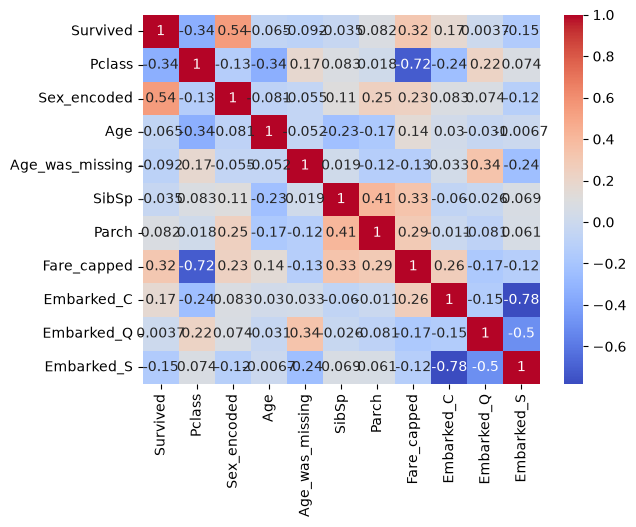

In [42]:
sns.heatmap(
    model_ready.corr(numeric_only=True), 
    annot=True, 
    cmap="coolwarm"
    )
plt.show()

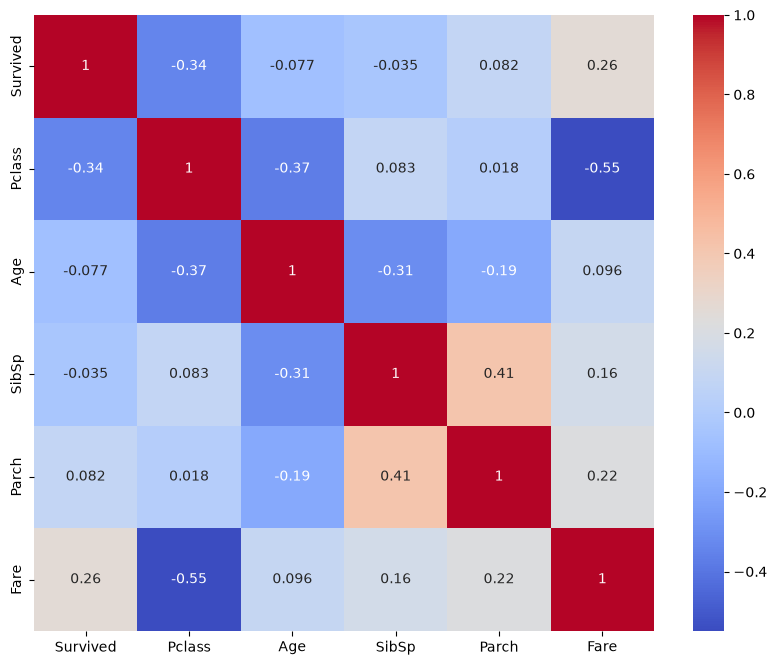

In [43]:
plt.figure(figsize=(10, 8))
cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
plt.show()